# Project: Who Is Going To Default On This Loan?

A complete machine learning project in PySpark, from a raw file to a model you could
defend in a meeting. Everything runs in Google Colab. Nothing to upload, nothing to
install by hand except one cell.

## What you are going to do

1. Make the data, then **look at it** before modelling anything.
2. Split it into a training part and a testing part, and understand why.
3. Build **seven pipelines**. Every one reads the same data and the same split. Each
   one changes exactly one thing from the pipeline before it.
4. Score all seven on **accuracy** and on **ROC AUC**, and find out which changes
   actually helped.

## The seven pipelines, as a plan

| | What changes | The question it asks |
|---|---|---|
| 1 | Numbers only, logistic regression | How far do the numeric columns alone get us? |
| 2 | Add the text columns as plain numbers | Do the text columns help? |
| 3 | Encode those text columns properly instead | Does *how* we encode them matter? |
| 4 | Also rescale the numbers | Does scaling help a linear model? |
| 5 | Swap in a decision tree | Does a different kind of model do better? |
| 6 | Use a whole forest of trees | Does averaging many trees help? |
| 7 | Let Spark tune the best one | How much is left in tuning? |

**Two of those seven changes turn out not to help at all.** That is not a mistake in the
notebook. Finding out which ideas do nothing is most of what this job is.

## How to read this notebook

Run the cells in order, top to bottom. Before every code cell there is a short
explanation of what it is about to do, and after it a note on what you should see.
Nothing assumes you have done machine learning before.

Expect about five minutes in total, most of it the first install cell.

# Step 1. Start Spark

**What Spark is, in one sentence:** a program that can hold a table too big for one
computer and run your query across many computers at once. We only have one computer
here, so everything will be fast, but the code you write is the same code that would
run on a hundred machines.

In [1]:
from pyspark.sql import SparkSession, functions as F, Window

spark = (SparkSession.builder
         .appName('LoanDefaultProject')
         .config('spark.sql.shuffle.partitions', '4')   # small data, so few pieces
         .getOrCreate())

spark.sparkContext.setLogLevel('ERROR')   # hide Spark's very chatty log messages

print('Spark version:', spark.version)

Spark version: 4.0.4


**What you should see.** `Spark version: 4.0.4`. If you get an error about Java,
re-run the cell once; Colab occasionally needs a second try.

`spark.sql.shuffle.partitions` is set to 4 because our data is tiny. The default is
200, which would make Spark create 200 nearly empty pieces of work and waste more time
managing them than computing.

## The data dictionary

Always write one of these. It is the difference between a model you can explain and a
pile of columns.

| Column | What it is | Type |
|---|---|---|
| `application_id` | The application number. **An identifier, never a feature.** | text |
| `income` | Yearly income in dollars | number |
| `loan_amount` | How much they are asking to borrow | number |
| `interest_rate` | The rate the bank offered, in percent | number |
| `dti` | Debt to income ratio: what fraction of income already goes to debt | number |
| `credit_score` | The usual 300 to 850 score. **Some are missing.** | number |
| `months_employed` | How long in the current job | number |
| `purpose` | What the loan is for: a car, a small business, and so on | text |
| `home_ownership` | `RENT`, `OWN` or `MORTGAGE` | text |
| `grade` | The bank's own risk grade, `A` (safest) to `G` (riskiest) | text |
| `region` | Which part of the country | text |
| `defaulted` | **The label.** `Yes` means they failed to repay | text |

Two things to notice before you write any code:

- **`application_id` must never go into the model.** It is a different number for every
  row, so a model can memorize it and will learn nothing that works on new applications.
- **Four of the columns are text**, and a model can only do arithmetic. Turning those
  into numbers is what pipelines 2 and 3 are about, and it turns out to matter a lot.

In [4]:
# Read the file with Spark. This is the real starting point of the project.
data = spark.read.csv('/content/loan_applications.csv',
                      header=True,        # the first line holds column names
                      inferSchema=True)   # let Spark work out which columns are numbers

print('applications:', data.count())
print()
data.printSchema()
data.show(5)

# Name the two groups of columns once, here, so every later cell can reuse them.
NUMERIC = ['income', 'loan_amount', 'interest_rate', 'dti', 'credit_score',
           'months_employed']
CATS    = ['purpose', 'home_ownership', 'grade', 'region']

print()
print('%d numeric feature columns :' % len(NUMERIC), NUMERIC)
print('%d text feature columns    :' % len(CATS), CATS)
print('not features              : application_id (an id) and defaulted (the label)')

applications: 6000

root
 |-- application_id: string (nullable = true)
 |-- income: integer (nullable = true)
 |-- loan_amount: integer (nullable = true)
 |-- interest_rate: double (nullable = true)
 |-- dti: double (nullable = true)
 |-- credit_score: integer (nullable = true)
 |-- months_employed: integer (nullable = true)
 |-- purpose: string (nullable = true)
 |-- home_ownership: string (nullable = true)
 |-- grade: string (nullable = true)
 |-- region: string (nullable = true)
 |-- defaulted: string (nullable = true)

+--------------+------+-----------+-------------+-----+------------+---------------+------------------+--------------+-----+---------+---------+
|application_id|income|loan_amount|interest_rate|  dti|credit_score|months_employed|           purpose|home_ownership|grade|   region|defaulted|
+--------------+------+-----------+-------------+-----+------------+---------------+------------------+--------------+-----+---------+---------+
|        L00001| 76779|      15538| 

**What you should see.** 6,000 applications, and a schema where `income` and
`credit_score` are `integer`, `dti` and `interest_rate` are `double`, and the four text
columns are `string`.

`inferSchema=True` is why Spark knows `income` is a number and not text. It costs one
extra pass over the file. Without it, every column comes back as a string and your
averages fail in confusing ways.

The cell also names two lists, **`NUMERIC`** and **`CATS`**, which every later cell reuses.
Writing the column names down once, in one place, is a small habit that saves a
surprising amount of debugging: when you add a column later you change one line, not nine.

# Step 3. Look at the data before modelling it

This step gets skipped by beginners and never by professionals. Three questions, in
order.

## Question 1: how common is the thing we are predicting?

In [5]:
# Count the two outcomes.
balance = data.groupBy('defaulted').count().orderBy('defaulted')
balance.show()

total = data.count()
# F.col (where F is an alias for pyspark.sql.functions)
n_default = data.filter(F.col('defaulted') == 'Yes').count()

print('default rate: %.1f%%' % (100.0 * n_default / total))
print()
print('So a model that simply says "No" to everybody would be right %.1f%% of the time.'
      % (100.0 * (total - n_default) / total))

+---------+-----+
|defaulted|count|
+---------+-----+
|       No| 4854|
|      Yes| 1146|
+---------+-----+

default rate: 19.1%

So a model that simply says "No" to everybody would be right 80.9% of the time.


**What you should see.** About **19.1 percent** of applications defaulted: 1,146 out of 6,000.

Read that last line again, because it is the single most useful number in the notebook.
**A model that always says "will not default" is already 80.9 percent accurate**, and it
is completely useless, because it never finds a single defaulter.

That is why accuracy alone cannot be trusted, and it is why we will also measure
**AUC**, which asks a different question: does the model give higher risk scores to the
people who actually defaulted? Always saying "No" scores 0.5 on AUC, which is the score
for guessing.

In [6]:
# Question 2: are any values missing?
print('missing values per column:')
for c in data.columns:
    n_missing = data.filter(F.col(c).isNull()).count()
    if n_missing:
        print('   %-18s %d missing  (%.1f%%)' % (c, n_missing, 100.0*n_missing/total))
print()
print('(columns not listed have no missing values)')

missing values per column:
   credit_score       240 missing  (4.0%)

(columns not listed have no missing values)


**What you should see.** **240 missing `credit_score` values**, which is 4.0 percent, and
nothing else missing.

Spark will not train a model on rows with holes in them. We have two choices: throw
those 240 applications away, or fill the gap with a sensible guess. We will fill them,
using a pipeline stage called `Imputer`, because throwing away 4 percent of your data to
avoid one missing column is a bad trade.

defaulted   income  loan_amount  interest_rate   dti  credit_score  months_employed
       No 68795.31     14004.41          11.80 18.89        709.29            60.16
      Yes 66980.26     14274.20          18.93 20.31        633.27            57.41


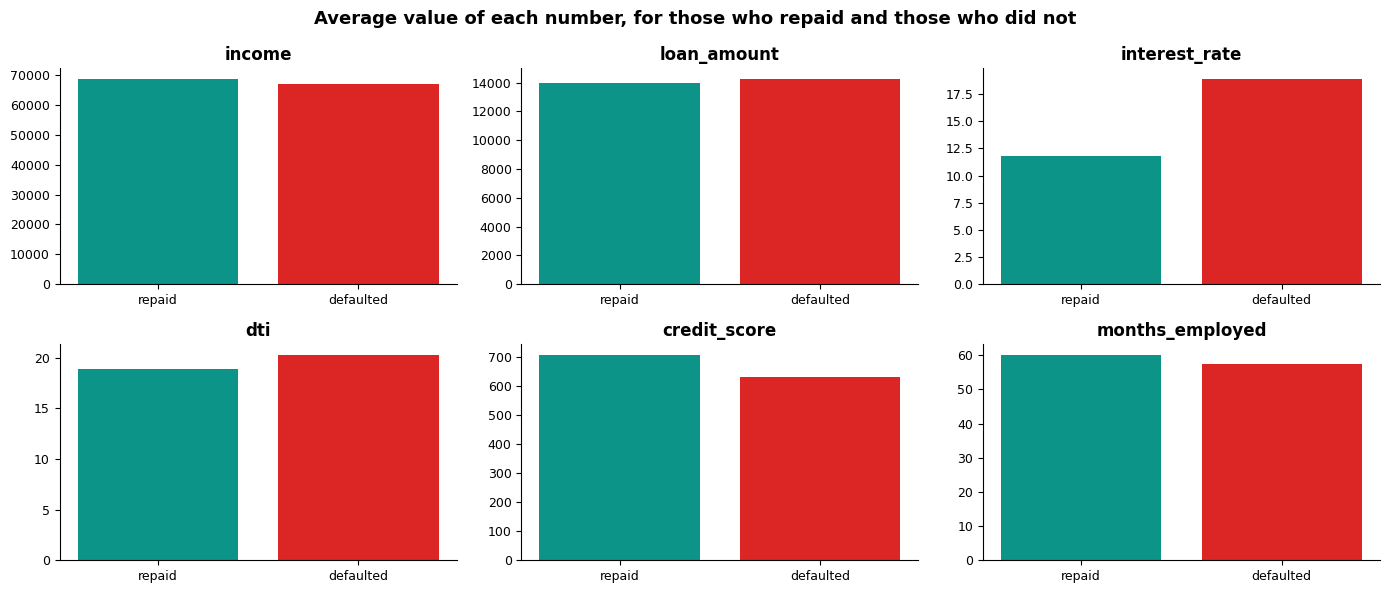

In [7]:
# Question 3: do the numeric columns actually separate the two groups?
# Aggregate in Spark, then bring the small summary to Python to draw it.
import matplotlib.pyplot as plt

summary = (data.groupBy('defaulted')
               .agg(*[F.round(F.avg(c), 2).alias(c) for c in NUMERIC])
               .orderBy('defaulted')
               .toPandas())
print(summary.to_string(index=False))

fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for ax, c in zip(axes.flat, NUMERIC):
    vals = summary.set_index('defaulted')[c]
    ax.bar(['repaid', 'defaulted'], [vals['No'], vals['Yes']],
           color=['#0D9488', '#DC2626'])
    ax.set_title(c, fontsize=12, fontweight='bold')
    ax.tick_params(labelsize=9)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
fig.suptitle('Average value of each number, for those who repaid and those who did not',
             fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

**How to read this.** Where the two bars differ, the column carries information. Where
they are the same height, it probably does not.

You should see a clear gap on **`interest_rate`** (defaulters were charged more),
**`credit_score`** (defaulters had lower scores) and **`dti`** (defaulters already owed
more). `income`, `loan_amount` and `months_employed` differ much less.

**The pattern worth naming:** `interest_rate` looks powerful because the bank already
priced the risk. The bank's own opinion is baked into that column. That is not cheating
here, because the rate is set before the loan is issued and so is known at prediction
time, but it is exactly the kind of column you must check the timing of. A column that
is only filled in *after* the outcome is called a **leak**, and it will make your model
look brilliant and be worthless.

**Note the `toPandas()` call.** Spark did the heavy counting across all 6,000 rows; we
then pulled the tiny two row summary into ordinary Python to draw it. That is the right
habit: **aggregate big, plot small.** Never call `toPandas()` on a full dataset.

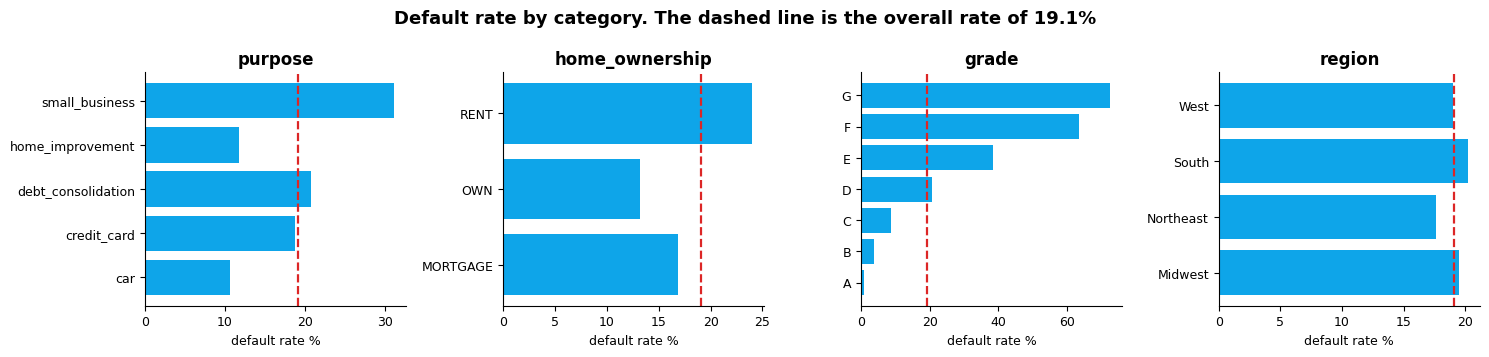

In [8]:
# And the text columns: what is the default rate inside each category?
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))

for ax, c in zip(axes, CATS):
    rates = (data.groupBy(c)
                 .agg((F.avg((F.col('defaulted') == 'Yes').cast('double')) * 100)
                      .alias('rate'))
                 .orderBy(c)
                 .toPandas())
    ax.barh(rates[c], rates['rate'], color='#0EA5E9')
    ax.axvline(100.0 * n_default / total, color='#DC2626', ls='--', lw=1.6)
    ax.set_title(c, fontsize=12, fontweight='bold')
    ax.set_xlabel('default rate %', fontsize=9)
    ax.tick_params(labelsize=9)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
fig.suptitle('Default rate by category. The dashed line is the overall rate of %.1f%%'
             % (100.0 * n_default / total), fontsize=13, fontweight='bold')
fig.tight_layout()
plt.show()

**How to read this.** A bar far from the dashed line means that category behaves
differently from the average, so the column is worth having.

You should see:

- **`grade`** steps up neatly from A to G. The bank's grading works.
- **`purpose`** is strong but **not in order**: `small_business` is the riskiest by a
  distance, `car` and `home_improvement` are the safest. There is no natural first,
  second, third here.
- **`home_ownership`**: renters default more than owners.
- **`region`**: all four bars sit on the line. **This column appears to carry nothing.**

Hold on to the `purpose` observation. The fact that its categories have no natural
order is exactly what pipelines 2 and 3 are about.

# Step 4. The split, and why it is not optional

We now cut the data in two:

- **70 percent to train on.** The model is allowed to look at these and learn from them.
- **30 percent to test on.** The model never sees these during training. We use them
  once, at the end, to find out how good it really is.

**Why bother?** Because a model can memorize. If you train and test on the same rows,
you are marking an exam with the answer sheet in front of you. A model that memorized
every row would score 100 percent and then fail completely on the next real applicant.

The `seed=42` makes the split the same every time you run it, so your numbers match the
ones written in this notebook.

In [9]:
from pyspark.ml.feature import StringIndexer

# The label must be a number: 0 or 1. StringIndexer gives the most common value 0,
# so 'No' becomes 0.0 and 'Yes' becomes 1.0.
label_maker = StringIndexer(inputCol='defaulted', outputCol='label')
data = label_maker.fit(data).transform(data)

data.groupBy('defaulted', 'label').count().orderBy('label').show()

train, test = data.randomSplit([0.7, 0.3], seed=42)

print('training on %d applications' % train.count())
print('testing  on %d applications  (the model never sees these while learning)'
      % test.count())

+---------+-----+-----+
|defaulted|label|count|
+---------+-----+-----+
|       No|  0.0| 4854|
|      Yes|  1.0| 1146|
+---------+-----+-----+

training on 4280 applications
testing  on 1720 applications  (the model never sees these while learning)


**What you should see.** `No` became label `0.0`, `Yes` became `1.0`, and the split gave
**4,280 training rows and 1,720 test rows**.

Those are not exactly 70 and 30 percent of 6,000. `randomSplit` decides row by row, like
flipping a weighted coin for each one, so it lands near the target rather than exactly on
it. That is normal and nothing to fix.

# Step 5. What a pipeline is, before we build seven of them

Everything from here uses **pipelines**, so it is worth two minutes on what they are.

## The two verbs: fit and transform

Spark ML has exactly two kinds of thing, and telling them apart explains everything else.

| | What it is | What you call on it |
|---|---|---|
| **Transformer** | Already knows what to do | `.transform(df)` |
| **Estimator** | Has to look at the data first, to learn something | `.fit(df)`, which **returns a Transformer** |

`StringIndexer` is an Estimator: it must read the data to find out which categories
exist. Calling `.fit()` on it gives you a `StringIndexerModel`, which is a Transformer
and now knows the category list. The cell below shows that happening.

In [10]:
# A tiny demonstration of fit versus transform, on one column.
indexer = StringIndexer(inputCol='grade', outputCol='grade_demo')
print('before fit :', type(indexer).__name__, '  <- an Estimator, it knows nothing yet')

indexer_model = indexer.fit(train)
print('after  fit :', type(indexer_model).__name__, '  <- a Transformer, it learned the list')
print('the list it learned:', indexer_model.labels)

indexer_model.transform(train).select('grade', 'grade_demo').show(5)

before fit : StringIndexer   <- an Estimator, it knows nothing yet
after  fit : StringIndexerModel   <- a Transformer, it learned the list
the list it learned: ['A', 'B', 'C', 'D', 'E', 'F', 'G']
+-----+----------+
|grade|grade_demo|
+-----+----------+
|    A|       0.0|
|    A|       0.0|
|    E|       4.0|
|    E|       4.0|
|    E|       4.0|
+-----+----------+
only showing top 5 rows


**What you should see.** `StringIndexer` turned into `StringIndexerModel` after `.fit()`,
and it printed the grades it found, ordered by how common they are.

Look at that order carefully: it is `A, B, C, D, E, F, G` here only because grade A
happens to be the most common. **StringIndexer orders by frequency, not by meaning.**
That is the trap pipeline 2 walks into.

## Why bundle the stages into a Pipeline

Doing these steps by hand means calling `fit` and `transform` in the right order, on the
right data, six or seven times, and then doing it again, identically, when you score new
applications. One slip and your model is quietly wrong.

A `Pipeline` is a list of stages. You call `.fit()` once on the whole list, and Spark
runs them in order and hands you back a `PipelineModel` that remembers everything. When
new data arrives you call `.transform()` once, and it is impossible to apply the steps in
the wrong order, because you no longer apply them yourself.

## The helper we will reuse seven times

To keep the seven pipelines comparable, the next cell defines one function that fits a
pipeline, scores it on the test set, records the result and prints it. After that, **the
only thing that changes between pipelines is the list of stages**, which is exactly the
point.

In [11]:
from pyspark.ml import Pipeline
from pyspark.ml.feature import OneHotEncoder, VectorAssembler, Imputer, StandardScaler
from pyspark.ml.classification import (LogisticRegression, DecisionTreeClassifier,
                                       RandomForestClassifier)
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.functions import vector_to_array
import time

# AUC: does the model give higher scores to the people who really defaulted?
auc_scorer = BinaryClassificationEvaluator(labelCol='label', metricName='areaUnderROC')

results = []        # we will collect every pipeline's scores in here


def run_pipeline(name, stages, note=''):
    """Fit a pipeline on train, score it on test, remember the numbers."""
    t0 = time.time()
    model = Pipeline(stages=stages).fit(train)       # one call fits every stage
    pred = model.transform(test)                     # one call applies every stage

    auc = auc_scorer.evaluate(pred)
    accuracy = pred.filter(F.col('prediction') == F.col('label')).count() / pred.count()

    results.append({'name': name, 'accuracy': accuracy, 'auc': auc,
                    'model': model, 'pred': pred})
    print('%-36s accuracy = %.4f    AUC = %.4f    (%.0fs) %s'
          % (name, accuracy, auc, time.time() - t0, note))
    return model


# Stages we reuse in several pipelines, defined once here.
NUMERIC_FILLED = ['income', 'loan_amount', 'interest_rate', 'dti',
                  'credit_score_filled', 'months_employed']

filler = Imputer(inputCols=['credit_score'],
                 outputCols=['credit_score_filled'],
                 strategy='median')     # fill the 240 holes with the middle value

indexers = [StringIndexer(inputCol=c, outputCol=c + '_idx', handleInvalid='keep')
            for c in CATS]

onehot = OneHotEncoder(inputCols=[c + '_idx' for c in CATS],
                       outputCols=[c + '_oh' for c in CATS])

print('helper ready. Each pipeline below changes only its stage list.')

helper ready. Each pipeline below changes only its stage list.


**What the three shared stages do.**

- **`Imputer`** fills the 240 missing credit scores with the median of the ones we have.
  It is an Estimator, because it has to look at the data to find that median. Note that
  it will learn the median from the **training rows only**, which is correct: the test
  rows must stay untouched.
- **`StringIndexer`**, one per text column, turns categories into numbers 0, 1, 2 and so
  on.
- **`OneHotEncoder`** takes those numbers and turns each into a set of yes/no columns.
  Pipeline 3 explains why.

`VectorAssembler`, which appears in every pipeline below, glues all the chosen feature
columns into the single column named `features` that Spark ML models expect. It is the
one piece of Spark ML that looks strangest at first and matters least conceptually: it
is just packing.

# Pipeline 1: the numbers only

**The change:** nothing yet. This is the baseline. Six numeric columns, the missing
scores filled, a logistic regression.

**Logistic regression**, in one sentence: it gives every column a weight, adds up
`weight x value` across the columns, and squashes the total into a probability between 0
and 1. It is the simplest useful classifier, and because you can read its weights, it is
the one you can explain to a regulator.

**The question:** how far do the numbers alone get us?

In [12]:
p1 = run_pipeline('P1  numbers only + LR', [
    filler,
    VectorAssembler(inputCols=NUMERIC_FILLED, outputCol='features'),
    LogisticRegression(featuresCol='features', labelCol='label', maxIter=50),
])

P1  numbers only + LR                accuracy = 0.8343    AUC = 0.8473    (12s) 


**What you should see.** Accuracy around **0.8343**, AUC around **0.8473**.

Put those two numbers side by side with what we learned in Step 3:

- Always saying "No" gives accuracy **0.809**. Our model gives **0.834**. So all that
  work bought about two and a half points of accuracy over doing nothing at all.
- But AUC went from **0.5** (guessing) to **0.847**, which is a large move. The model is
  genuinely ranking risky applicants above safe ones.

This is the clearest early example of why you need both numbers. Accuracy makes the model
look barely better than nothing. AUC shows it has learned a great deal.

# Pipeline 2: add the text columns, the obvious way

**The change:** add the four text columns, turned into numbers by `StringIndexer`.

So `purpose` becomes 0, 1, 2, 3, 4. `grade` becomes 0 to 6. This is often called **label
encoding**, and it is the first thing everybody tries.

**The question:** do the text columns help?

In [13]:
p2 = run_pipeline('P2  + label-encoded text + LR', [
    filler,
    *indexers,
    VectorAssembler(inputCols=NUMERIC_FILLED + [c + '_idx' for c in CATS],
                    outputCol='features'),
    LogisticRegression(featuresCol='features', labelCol='label', maxIter=50),
], note='<- four new columns')

P2  + label-encoded text + LR        accuracy = 0.8349    AUC = 0.8491    (10s) <- four new columns


**What you should see.** Accuracy around **0.8349**, AUC around **0.8491**.

Compare with pipeline 1: AUC went from 0.8473 to 0.8491. That is a gain of **0.0018**,
which across 1,720 test rows is indistinguishable from noise. **Four real columns bought
us essentially nothing.**

## Why adding four real columns bought nothing

We know from the chart in Step 3 that `purpose` and `grade` matter a lot. So why did the
model not use them?

Because of what the numbers now mean. `StringIndexer` gave `purpose` the values 0 to 4,
ordered by how common each category is. A logistic regression gives that column **one
weight**. One weight can only express "as this number goes up, risk goes steadily up" or
"steadily down".

But the real pattern is not steady at all. In index order the risks are roughly:

| index | purpose | risk |
|---|---|---|
| 0 | debt_consolidation | higher |
| 1 | credit_card | average |
| 2 | home_improvement | **lower** |
| 3 | small_business | **much higher** |
| 4 | car | **lower** |

Up, down, up, down. No single weight can trace that line. The model's best option is a
weight near zero, which is the same as ignoring the column.

**The number 3 does not mean "three times category 1".** We invented an ordering that is
not real, and the model took us at our word.

# Pipeline 3: encode the text properly

**The change:** keep everything from pipeline 2, but put `OneHotEncoder` after the
indexers.

**One-hot encoding** replaces one column holding 0 to 4 with five yes/no columns:

```
purpose = small_business     becomes     is_debt_consolidation = 0
                                         is_credit_card        = 0
                                         is_home_improvement   = 0
                                         is_small_business     = 1
                                         is_car                = 0
```

Now the model has **one weight per category** instead of one weight for the whole column.
It can say "small_business, add a lot of risk" and "car, take some away" at the same
time, which is what the data actually looks like.

**The question:** does how we encode the text change anything?

In [14]:
p3 = run_pipeline('P3  + one-hot text + LR', [
    filler,
    *indexers,
    onehot,                                   # <-- the only new stage
    VectorAssembler(inputCols=NUMERIC_FILLED + [c + '_oh' for c in CATS],
                    outputCol='features'),
    LogisticRegression(featuresCol='features', labelCol='label', maxIter=50),
])

P3  + one-hot text + LR              accuracy = 0.8593    AUC = 0.8751    (10s) 


**What you should see.** Accuracy around **0.8593**, AUC around **0.8751**.

That is the biggest jump in the whole notebook:

| | accuracy | AUC |
|---|---|---|
| P2 label encoded | 0.8349 | 0.8491 |
| P3 one-hot | **0.8593** | **0.8751** |

One extra stage, worth **+0.0260 of AUC**.

**The data did not change. The split did not change. The model did not change.** The
only difference is one extra stage that changed how four columns were written down.

That is the lesson of this whole notebook in one comparison. Most of the gain available
in a real project is in how you prepare the features, not in which fancy model you pick.

# Pipeline 4: also rescale the numbers

**The change:** add `StandardScaler` so every numeric column is put on the same scale.

**The reasoning.** Our numbers live on wildly different scales. `income` runs to 150,000.
`dti` runs to 45. A weight of 0.001 on income can matter more than a weight of 1.0 on
dti, which makes the weights hard to compare and, for some algorithms, hard to find at
all. Rescaling puts them all in the same range.

**The question:** does this good idea actually help here?

In [15]:
p4 = run_pipeline('P4  + scaling + LR', [
    filler,
    *indexers,
    onehot,
    VectorAssembler(inputCols=NUMERIC_FILLED, outputCol='numeric_raw'),
    StandardScaler(inputCol='numeric_raw', outputCol='numeric_scaled'),
    VectorAssembler(inputCols=['numeric_scaled'] + [c + '_oh' for c in CATS],
                    outputCol='features'),
    LogisticRegression(featuresCol='features', labelCol='label', maxIter=50),
])

P4  + scaling + LR                   accuracy = 0.8593    AUC = 0.8751    (11s) 


**What you should see.** Accuracy **0.8593**, AUC **0.8751**. Identical to pipeline 3, to
four decimal places.

## An honest negative result

Scaling is genuinely good advice, and it did nothing here. Both are true.

The reason is that Spark's logistic regression uses a solver called **L-BFGS**, which
handles badly scaled inputs on its own. Scaling matters enormously for algorithms that
cannot, such as k-nearest neighbours, k-means, or neural networks, and for anything using
plain gradient descent.

**Keep this slide in your head when somebody lists best practices at you.** A practice is
only worth the time it takes if it changes an answer you can measure. We measured, and it
did not. We will keep the simpler pipeline 3.

# Pipeline 5: a completely different kind of model

**The change:** swap logistic regression for a **decision tree**, and go back to the
label-encoded features.

**A decision tree**, in one sentence: a flowchart of yes/no questions learned from the
data, like "is credit_score below 660? if yes, is dti above 25?", ending in a verdict.

**Why go back to label encoding?** Because trees do not have the problem pipeline 2 ran
into. A tree does not multiply the category number by a weight; it splits on it, and it
can split the same column many times. The fake ordering does not hurt it. **Trees do not
need one-hot encoding**, and giving them one-hot columns often makes them worse by
splitting the data too thinly.

**The question:** does a different kind of model beat the linear one?

In [16]:
p5 = run_pipeline('P5  label-encoded + DecisionTree', [
    filler,
    *indexers,
    VectorAssembler(inputCols=NUMERIC_FILLED + [c + '_idx' for c in CATS],
                    outputCol='features'),
    DecisionTreeClassifier(featuresCol='features', labelCol='label',
                           maxDepth=5, seed=42),
], note='<- watch the two numbers disagree')

P5  label-encoded + DecisionTree     accuracy = 0.8326    AUC = 0.7474    (6s) <- watch the two numbers disagree


**What you should see.** Accuracy around **0.8326**, AUC around **0.7474**.

## Stop and look at this. The two measures disagree badly.

| | accuracy | AUC |
|---|---|---|
| P3 one-hot + LR | 0.8593 | 0.8751 |
| P5 decision tree | 0.8326 | **0.7474** |

Accuracy dropped about three points. **AUC fell off a cliff**, from 0.875 to 0.747.

**Why?** A single tree of depth 5 has at most 32 leaves. Every application that lands in
the same leaf gets **exactly the same probability**. So instead of 1,720 different risk
scores, the model produces about 30 distinct values. Accuracy does not care, because it
only asks whether each prediction was on the right side of 0.5. AUC does care, because it
is entirely about ranking, and you cannot rank finely with 30 values.

**The practical consequence.** If your job is to approve or decline, accuracy may be
enough. If your job is to produce a risk score that the pricing team will sort customers
by, this model is close to useless no matter how good its accuracy looks.

That is why the project measures both.

# Pipeline 6: a whole forest instead of one tree

**The change:** replace the single tree with a **random forest** of 120 trees.

**How a forest works:** build many trees, each on a random sample of the rows and a
random subset of the columns, then average their votes. Each tree is mediocre and wrong
in its own way, and averaging cancels much of that out. Because the average of 120 trees
can take many values, the probability scores become fine grained again.

**The question:** does averaging fix what the single tree got wrong?

In [17]:
p6 = run_pipeline('P6  label-encoded + RandomForest', [
    filler,
    *indexers,
    VectorAssembler(inputCols=NUMERIC_FILLED + [c + '_idx' for c in CATS],
                    outputCol='features'),
    RandomForestClassifier(featuresCol='features', labelCol='label',
                           numTrees=120, maxDepth=7, seed=42),
])

P6  label-encoded + RandomForest     accuracy = 0.8471    AUC = 0.8581    (17s) 


**What you should see.** Accuracy around **0.8471**, AUC around **0.8581**.

The forest rescued most of what the single tree lost: AUC went from 0.7474 back up to
0.8581. Averaging worked, exactly as advertised.

**But it still does not beat pipeline 3**, the plain logistic regression on one-hot
features, which scored 0.8751.

That is worth sitting with. The random forest is the more sophisticated model. It is
slower, it has more settings, and you cannot read its reasoning. And on this data it
loses to the simple one. We will come back to why in the final section.

# Pipeline 7: let Spark do the tuning

**The change:** take the winning recipe from pipeline 3 and let Spark search for better
settings, using **cross validation**.

Every model has settings nobody told us the right value for. For logistic regression the
two that matter are:

- **`regParam`**: how hard to push weights toward zero, which guards against the model
  trusting any one column too much.
- **`elasticNetParam`**: which style of that pushing to use.

**What cross validation does.** It splits the *training* data into 3 folds. For each
combination of settings it trains on 2 folds and scores on the third, three times over,
and averages. The test set is still never touched. With 6 combinations and 3 folds that
is 18 models, plus one final fit on all the training data.

**The question:** how much is left in tuning?

In [18]:
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder

# The recipe from pipeline 3, but with the model left adjustable.
lr = LogisticRegression(featuresCol='features', labelCol='label', maxIter=100)

tunable = Pipeline(stages=[
    filler,
    *indexers,
    onehot,
    VectorAssembler(inputCols=NUMERIC_FILLED + [c + '_oh' for c in CATS],
                    outputCol='features'),
    lr,
])

grid = (ParamGridBuilder()
        .addGrid(lr.regParam, [0.0, 0.01, 0.1])
        .addGrid(lr.elasticNetParam, [0.0, 0.5])
        .build())
print('settings to try:', len(grid), ' x 3 folds =', len(grid)*3, 'models, plus a final fit')

cv = CrossValidator(estimator=tunable, estimatorParamMaps=grid,
                    evaluator=auc_scorer, numFolds=3, parallelism=2, seed=42)

t0 = time.time()
cv_model = cv.fit(train)
pred = cv_model.transform(test)

auc = auc_scorer.evaluate(pred)
accuracy = pred.filter(F.col('prediction') == F.col('label')).count() / pred.count()
results.append({'name': 'P7  tuned LR (cross validated)', 'accuracy': accuracy,
                'auc': auc, 'model': cv_model, 'pred': pred})

best_lr = cv_model.bestModel.stages[-1]
print('%-36s accuracy = %.4f    AUC = %.4f    (%.0fs)'
      % ('P7  tuned LR (cross validated)', accuracy, auc, time.time() - t0))
print()
print('settings it chose:  regParam = %s   elasticNetParam = %s'
      % (best_lr.getRegParam(), best_lr.getElasticNetParam()))

settings to try: 6  x 3 folds = 18 models, plus a final fit
P7  tuned LR (cross validated)       accuracy = 0.8599    AUC = 0.8748    (87s)

settings it chose:  regParam = 0.01   elasticNetParam = 0.0


**What you should see.** Accuracy around **0.8599**, AUC around **0.8748**, and the search
choosing `regParam = 0.01`, `elasticNetParam = 0.0`.

Compare with pipeline 3, which it was tuning:

| | accuracy | AUC |
|---|---|---|
| P3 untuned | 0.8593 | **0.8751** |
| P7 tuned | **0.8599** | 0.8748 |

Read that carefully, because it is not the clean win you were expecting. After fitting 19
models, tuning gained **0.0006 of accuracy** and **lost 0.0003 of AUC**.

**That is the honest shape of tuning.** Both differences are far too small to mean
anything. Choosing one-hot encoding over label encoding, back in pipeline 3, was worth
**+0.0260 of AUC**. Tuning the model afterwards was worth nothing measurable.

Beginners spend their afternoons on tuning. The gains are in the features, and this
notebook has just measured the difference.

# Step 6. Compare all seven

Everything so far has been one pipeline at a time. Now put them side by side.

                        pipeline  accuracy    AUC
         P3  + one-hot text + LR    0.8593 0.8751
              P4  + scaling + LR    0.8593 0.8751
  P7  tuned LR (cross validated)    0.8599 0.8748
P6  label-encoded + RandomForest    0.8471 0.8581
   P2  + label-encoded text + LR    0.8349 0.8491
           P1  numbers only + LR    0.8343 0.8473
P5  label-encoded + DecisionTree    0.8326 0.7474


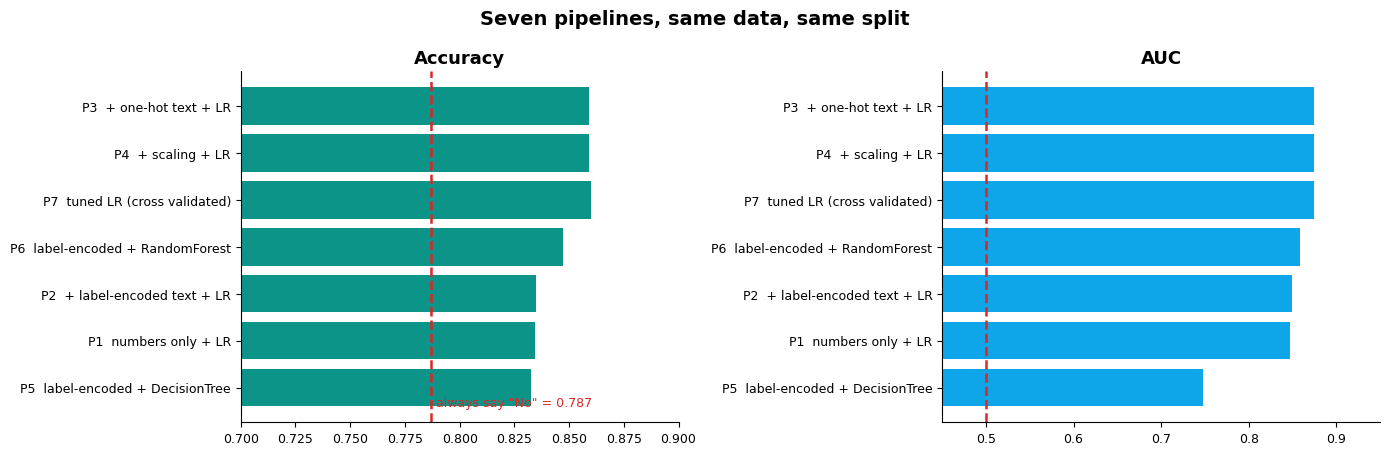

In [19]:
import pandas as pd

table = pd.DataFrame([{'pipeline': r['name'],
                       'accuracy': round(r['accuracy'], 4),
                       'AUC': round(r['auc'], 4)} for r in results])
table = table.sort_values('AUC', ascending=False).reset_index(drop=True)
print(table.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
order = table.iloc[::-1]          # smallest at the bottom of the chart

axes[0].barh(order['pipeline'], order['accuracy'], color='#0D9488')
axes[0].axvline(0.787, color='#DC2626', ls='--', lw=1.8)
axes[0].text(0.789, -0.4, 'always say "No" = 0.787', color='#DC2626', fontsize=9)
axes[0].set_xlim(0.70, 0.90)
axes[0].set_title('Accuracy', fontsize=13, fontweight='bold')

axes[1].barh(order['pipeline'], order['AUC'], color='#0EA5E9')
axes[1].axvline(0.5, color='#DC2626', ls='--', lw=1.8)
axes[1].set_xlim(0.45, 0.95)
axes[1].set_title('AUC', fontsize=13, fontweight='bold')

for ax in axes:
    ax.tick_params(labelsize=9)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)
fig.suptitle('Seven pipelines, same data, same split', fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

**What you should see.** A ranking close to this:

| pipeline | accuracy | AUC | what the change was worth |
|---|---|---|---|
| P3 one-hot + LR | 0.8593 | **0.8751** | **the big win, +0.0260 AUC** |
| P4 + scaling | 0.8593 | 0.8751 | nothing at all |
| P7 tuned LR | **0.8599** | 0.8748 | +0.0006 accuracy, -0.0003 AUC |
| P6 random forest | 0.8471 | 0.8581 | recovered most of what P5 lost |
| P2 label-encoded | 0.8349 | 0.8491 | +0.0018 AUC, which is noise |
| P1 numbers only | 0.8343 | 0.8473 | the baseline |
| P5 decision tree | 0.8326 | 0.7474 | **went badly backwards on AUC** |

**The two charts do not agree on a winner.** P7 has the best accuracy. P3 and P4 have the
best AUC. P5 sits above both P1 and P2 on accuracy and far below them on AUC. If you had
measured only one of these numbers you would leave this project with a different
conclusion, which is the whole argument for reporting both.

# Step 7. The ROC curve

AUC is one number. The **ROC curve** is the picture that number summarizes, and it is
worth seeing once.

## What the curve is

Your model does not output "yes" or "no". It outputs a probability. To decide, you pick a
**threshold**: flag everybody above 0.5, say. But 0.5 is just a default, and you could
pick anything.

The ROC curve plots what happens at **every possible threshold**:

- going up the chart: the fraction of real defaulters you catch (**true positive rate**)
- going right: the fraction of good customers you wrongly flag (**false positive rate**)

A perfect model hugs the top left corner: catch everybody, accuse nobody. Guessing gives
the diagonal line. **AUC is literally the area underneath the curve**, so 1.0 is perfect
and 0.5 is the diagonal.

## Computing it in Spark

The cell below builds the curve without leaving Spark, using a **window function**. Sort
everybody by risk score, highest first, then walk down the list keeping a running count of
how many real defaulters you have passed and how many non-defaulters. Those two running
counts, divided by their totals, are exactly the two axes.

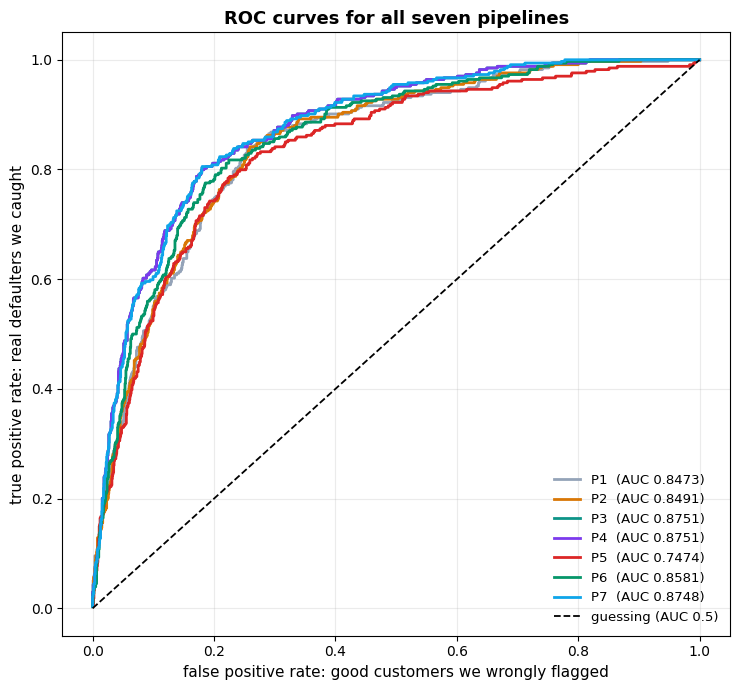

In [20]:
def roc_points(pred_df):
    """Return the ROC curve as a small pandas frame, computed inside Spark."""
    scored = pred_df.withColumn('p', vector_to_array('probability')[1])

    totals = scored.groupBy().agg(F.sum('label').alias('pos'),
                                  F.count('*').alias('n')).first()
    n_pos = float(totals['pos'])
    n_neg = float(totals['n'] - totals['pos'])

    # walk down the list from riskiest to safest, counting as we go
    running = Window.orderBy(F.desc('p')).rowsBetween(Window.unboundedPreceding,
                                                      Window.currentRow)
    curve = (scored.select('p', 'label')
             .withColumn('caught', F.sum('label').over(running))
             .withColumn('wrongly_flagged', F.sum(F.lit(1.0) - F.col('label')).over(running))
             .select((F.col('wrongly_flagged') / n_neg).alias('fpr'),
                     (F.col('caught') / n_pos).alias('tpr')))
    return curve.toPandas()


plt.figure(figsize=(7.5, 7))
colors = ['#94A3B8', '#D97706', '#0D9488', '#7C3AED', '#DC2626', '#059669', '#0EA5E9']

for r, col in zip(results, colors):
    pts = roc_points(r['pred'])
    plt.plot(pts['fpr'], pts['tpr'], lw=2.0, color=col,
             label='%s  (AUC %.4f)' % (r['name'].split('  ')[0], r['auc']))

plt.plot([0, 1], [0, 1], 'k--', lw=1.3, label='guessing (AUC 0.5)')
plt.xlabel('false positive rate: good customers we wrongly flagged', fontsize=11)
plt.ylabel('true positive rate: real defaulters we caught', fontsize=11)
plt.title('ROC curves for all seven pipelines', fontsize=13, fontweight='bold')
plt.legend(loc='lower right', fontsize=9.5, frameon=False)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**How to read this chart.**

- The **higher and further left** a curve sits, the better that pipeline is.
- The dashed diagonal is guessing. Any curve on it has learned nothing.
- **P5, the single decision tree, is the obvious outlier.** Its curve is made of a few
  long straight segments instead of a smooth arc, because the model only produces about 30
  distinct scores. You can see the coarseness directly.
- The top curves (P7, P3, P4) overlap almost exactly, which is what an AUC difference of
  0.0001 looks like.

**Reading a business decision off this chart.** Every point on a curve is one possible
threshold. The default threshold of 0.5 puts the winning pipeline at roughly
**(0.06, 0.53)**: it wrongly flags 6 percent of the good customers and catches 53 percent
of the defaulters. Step 8 prints those exact counts.

Slide right along the curve and you catch more defaulters while annoying more good
customers. Whether that trade is worth making depends on what a default costs you against
what a false accusation costs you. **The model cannot answer that and neither can AUC.**
Picking the point is the business's decision, and this chart is the map they need.

# Step 8. Where the winner goes wrong

AUC and accuracy are summaries. The **confusion matrix** shows the four things that can
actually happen, and it is the version a manager will understand.

In [21]:
best = max(results, key=lambda r: r['auc'])
print('best by AUC:', best['name'])
print()

cm = (best['pred'].groupBy('label', 'prediction').count()
      .orderBy('label', 'prediction').toPandas())

def get(lbl, prd):
    row = cm[(cm['label'] == lbl) & (cm['prediction'] == prd)]
    return int(row['count'].iloc[0]) if len(row) else 0

tn, fp = get(0.0, 0.0), get(0.0, 1.0)
fn, tp = get(1.0, 0.0), get(1.0, 1.0)

print('                        predicted')
print('                   repaid    defaulted')
print('actually repaid     %5d        %5d     <- %d good customers wrongly flagged'
      % (tn, fp, fp))
print('actually defaulted  %5d        %5d     <- %d defaulters missed'
      % (fn, tp, fn))
print()
print('accuracy  : %.4f   of everybody, how many did we get right' % ((tp+tn)/(tp+tn+fp+fn)))
print('recall    : %.4f   of the real defaulters, how many did we catch' % (tp/(tp+fn)))
print('precision : %.4f   of those we flagged, how many really defaulted' % (tp/(tp+fp)))

best by AUC: P3  + one-hot text + LR

                        predicted
                   repaid    defaulted
actually repaid      1301           85     <- 85 good customers wrongly flagged
actually defaulted    157          177     <- 157 defaulters missed

accuracy  : 0.8593   of everybody, how many did we get right
recall    : 0.5299   of the real defaulters, how many did we catch
precision : 0.6756   of those we flagged, how many really defaulted


**What you should see, and the uncomfortable part.**

```
                        predicted
                   repaid    defaulted
actually repaid      1301           85
actually defaulted    157          177
```

Accuracy of **0.8593** looks respectable. Then look at **recall of 0.5299**: of the 334
applicants who really defaulted, the model caught **177 and missed 157**. It finds barely
half of them.

How can accuracy be high while recall is only half? Because defaulters are 19 percent of
the data. Getting the other 81 percent right carries the accuracy almost by itself.

**If this were a real lending model, recall is the number the risk committee would ask
about first.** And the fix is not a better model, it is a lower threshold: flag everybody
above 0.3 instead of 0.5, catch far more defaulters, and accept more false alarms. That
is a business decision, and the ROC curve in Step 7 is the map for making it.

# Step 9. What did the model actually learn?

A model you cannot interrogate is a model you cannot defend. Two ways to look inside.

In [22]:
# 1. The forest's view: which columns did its trees find useful?
forest = p6.stages[-1]
feature_names = NUMERIC_FILLED + [c + '_idx' for c in CATS]
importances = sorted(zip(feature_names, forest.featureImportances.toArray()),
                     key=lambda t: t[1], reverse=True)

print('Random forest, feature importance:')
for name, score in importances:
    bar = '#' * int(round(score * 60))
    print('   %-20s %.4f  %s' % (name, score, bar))

Random forest, feature importance:
   grade_idx            0.3159  ###################
   interest_rate        0.2273  ##############
   credit_score_filled  0.1859  ###########
   purpose_idx          0.0535  ###
   dti                  0.0524  ###
   income               0.0466  ###
   months_employed      0.0360  ##
   loan_amount          0.0332  ##
   home_ownership_idx   0.0278  ##
   region_idx           0.0214  #


**What you should see.** Something close to this order:

| feature | importance |
|---|---|
| `grade_idx` | 0.3159 |
| `interest_rate` | 0.2273 |
| `credit_score_filled` | 0.1859 |
| `purpose_idx` | 0.0535 |
| `dti` | 0.0524 |
| ... | |
| `region_idx` | 0.0214 |

The top three carry roughly three quarters of the model between them, and all three say
the same thing in different words: **the bank's own risk assessment was already good**.
`grade` is its verdict, `interest_rate` is the price it set from that verdict, and
`credit_score` is the main input to both.

**And `region` sits at the bottom**, exactly as the chart back in Step 3 predicted. A
column that looked useless in the data turned out to be useless in the model. Those two
agreeing is a good sign that nothing has gone wrong.

In [23]:
# 2. The logistic regression's view: the actual weights, which you can read out loud.
lr_model = p3.stages[-1]
print('Logistic regression weights (one-hot pipeline).')
print('Positive means "raises the chance of default".')
print()

# the numeric weights come first, in the order we assembled them
for name, w in zip(NUMERIC_FILLED, lr_model.coefficients[:len(NUMERIC_FILLED)]):
    print('   %-22s %+.5f' % (name, w))
print('   %-22s %+.5f' % ('intercept', lr_model.intercept))

Logistic regression weights (one-hot pipeline).
Positive means "raises the chance of default".

   income                 -0.00001
   loan_amount            +0.00001
   interest_rate          +0.09114
   dti                    +0.04159
   credit_score_filled    -0.01155
   months_employed        -0.00153
   intercept              +3.92216


**How to read the weights.** `interest_rate` and `dti` should come out clearly positive:
a higher rate or more existing debt raises the predicted chance of default.
`credit_score_filled` should be negative: a higher score lowers it. Those signs match
what anybody in lending would tell you, and that agreement is the point. **A model whose
weights contradict the business is either broken or has found a leak.**

Do not compare the sizes of these numbers directly. `income` is measured in tens of
thousands and `dti` in single digits, so their weights are on completely different
scales. That is the problem `StandardScaler` solves, and it is the reason scaling is
still worth doing when you want to *read* the weights, even though pipeline 4 showed it
does not change the predictions.

---

# What this project taught

## The results, one more time

| pipeline | accuracy | AUC |
|---|---|---|
| P3 one-hot + logistic regression | 0.8593 | **0.8751** |
| P4 one-hot + scaling + LR | 0.8593 | 0.8751 |
| P7 tuned logistic regression | **0.8599** | 0.8748 |
| P6 random forest, 120 trees | 0.8471 | 0.8581 |
| P2 label-encoded + LR | 0.8349 | 0.8491 |
| P1 numbers only + LR | 0.8343 | 0.8473 |
| P5 single decision tree | 0.8326 | 0.7474 |

## Six things worth remembering

1. **Know your baseline before you celebrate.** Always saying "No" was already 80.9
   percent accurate, and our best model reached 86.0. Any accuracy you quote has to be read
   against the do-nothing number or it means very little.

2. **Accuracy and AUC can disagree, and the gap is informative.** The single tree had
   acceptable accuracy and terrible AUC, because it could only produce about 30 distinct
   scores. The two final charts even picked different winners. Which measure matters
   depends on whether you are making a decision or producing a ranking.

3. **How you encode your features beats which model you choose.** Switching from label
   encoding to one-hot was worth **+0.0260 AUC**. Tuning the model afterwards, across 19
   fits, was worth nothing measurable. That ratio is not unusual, and it is the most useful
   thing in this notebook.

4. **The fanciest model does not always win.** A 120 tree random forest lost to a plain
   logistic regression. Risk in this data really does build up by adding effects
   together, which is exactly the shape a linear model is built for. Match the model to
   the shape of the problem, not to its reputation.

5. **Negative results are results.** Scaling changed nothing to four decimal places. The
   professional move is to measure, report it, and keep the simpler pipeline.

6. **Pipelines are what make all of the above comparable.** Seven experiments, one data
   set, one split, one helper function, and the only thing that differed between runs was
   a list of stages. Without that discipline, you cannot tell whether your improvement
   came from the idea you were testing or from something you changed by accident.

## If something went wrong

| What you saw | What to do |
|---|---|
| `NameError: name 'spark' is not defined` | A cell was skipped. Run from the top, in order. |
| `AnalysisException: Path does not exist` | The data cell in Step 2 did not run. |
| Your numbers differ in the third decimal place | Normal. Spark's splits depend on partitioning. Anything close to the table above is the same result. |
| The cross validation cell is slow | Expected, it fits 19 models. About 25 seconds. |
| A chart is blank | Re-run that cell. Colab sometimes needs a second go at the first plot. |

## Try these

1. Delete `region` from `CATS` and re-run pipeline 3. The feature importance said it was
   worthless. Was it?
2. Change `maxDepth` on pipeline 5 from 5 to 12. Watch training accuracy rise and test
   AUC fall. That is overfitting, visible in two numbers.
3. Give the random forest the **one-hot** features instead of the label-encoded ones. It
   gets slightly worse. Explain why using what pipeline 5 told you about trees.
4. Lower the decision threshold to 0.3 by hand and recompute the confusion matrix. How
   many more defaulters do you catch, and how many good customers do you annoy?
5. Add `application_id` to the feature list and see what happens. Then explain why it is
   the single worst idea in this notebook.